# Projeto 5 — CNN no CIFAR-10

Configuração do PyTorch e carregamento das 10 classes do CIFAR-10. Execute a célula de download manualmente quando desejar.

In [22]:
import torch
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Versão do PyTorch: {torch.__version__}")
print(f"Dispositivo selecionado: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(device)}")
else:
    print("GPU: indisponível para o PyTorch; usando CPU.")

Versão do PyTorch: 2.11.0+cu128
Dispositivo selecionado: cuda
GPU: NVIDIA GeForce RTX 3060


## Download e carregamento do CIFAR-10

A próxima célula baixa os dados para `data/` na primeira execução e reutiliza os arquivos nas execuções seguintes.

In [23]:
transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(root="data", train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root="data", train=False, download=True, transform=transform)

In [24]:
print(f"Imagens de treino: {len(train_dataset):,}")
print(f"Imagens de teste: {len(test_dataset):,}")
print(f"Classes ({len(train_dataset.classes)}): {', '.join(train_dataset.classes)}")

Imagens de treino: 50,000
Imagens de teste: 10,000
Classes (10): airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck


## Pré-processamento

Usamos seed 42 para separar 4.500 imagens de cada classe para treino e 500 para validação. O teste permanece separado. A normalização usa média e desvio 0,5 por canal, convertendo os pixels de [0, 1] para [-1, 1], sem estimar estatísticas na validação ou no teste.

In [25]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset

SEED = 42
BATCH_SIZE = 128
mean = (0.5, 0.5, 0.5)
std = (0.5, 0.5, 0.5)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
train_dataset.transform = transform
test_dataset.transform = transform

targets = torch.tensor(train_dataset.targets)
classes = train_dataset.classes
split_generator = torch.Generator().manual_seed(SEED)
train_indices, val_indices = [], []

for class_id in range(len(classes)):
    indices = torch.where(targets == class_id)[0]
    indices = indices[torch.randperm(len(indices), generator=split_generator)]
    val_indices.extend(indices[:500].tolist())
    train_indices.extend(indices[500:].tolist())

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)

assert len(train_subset) == 45_000 and len(val_subset) == 5_000
assert set(train_indices).isdisjoint(val_indices)
assert len(set(train_indices + val_indices)) == len(train_dataset)
print(f'Treino: {len(train_subset)} | Validação: {len(val_subset)} | Teste: {len(test_dataset)}')

Treino: 45000 | Validação: 5000 | Teste: 10000


### DataLoaders

Somente o treino é embaralhado. Usamos `num_workers=0` para facilitar a execução no Jupyter no Windows. As imagens são carregadas em lotes, sem enviar o dataset inteiro para a GPU.

In [26]:
loader_options = dict(batch_size=BATCH_SIZE, num_workers=0, pin_memory=device.type == 'cuda')
train_loader = DataLoader(train_subset, shuffle=True,generator=torch.Generator().manual_seed(SEED), **loader_options)
val_loader = DataLoader(val_subset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

print(f'Lotes — treino: {len(train_loader)}, validação: {len(val_loader)}, teste: {len(test_loader)}')

Lotes — treino: 352, validação: 40, teste: 79


### Imagens e distribuição das classes

Exibimos uma imagem de treino por classe, desfazendo a normalização apenas para visualização. A distribuição usa somente os rótulos.

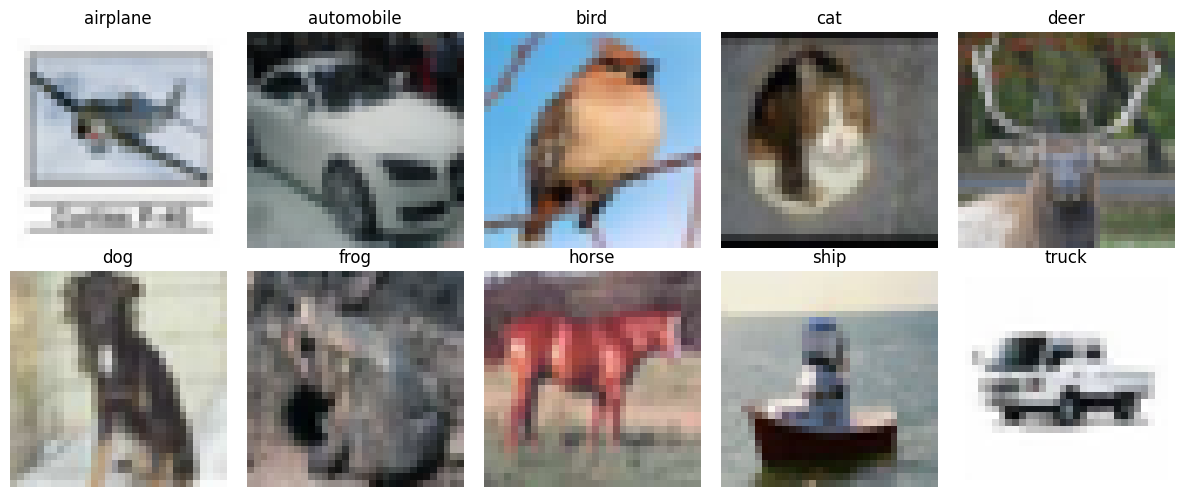

Classe           Treino  Validação    Teste
airplane           4500        500     1000
automobile         4500        500     1000
bird               4500        500     1000
cat                4500        500     1000
deer               4500        500     1000
dog                4500        500     1000
frog               4500        500     1000
horse              4500        500     1000
ship               4500        500     1000
truck              4500        500     1000


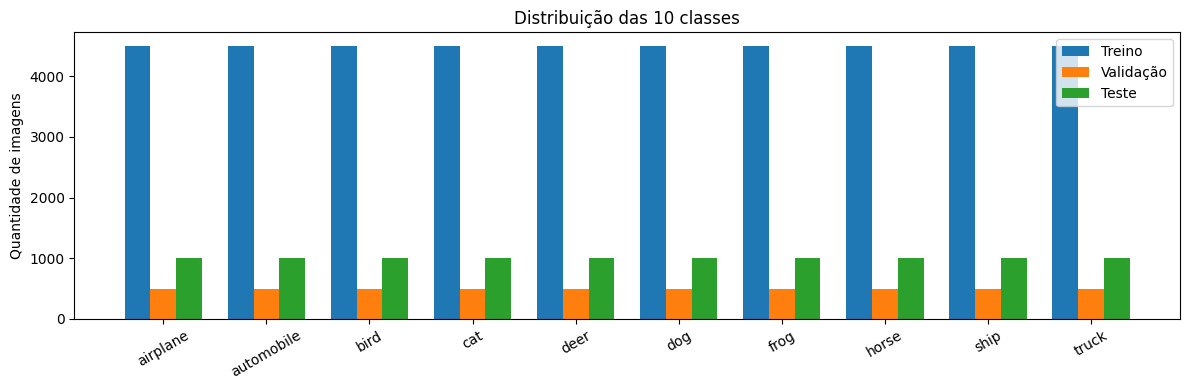

In [27]:
mean_tensor = torch.tensor(mean).view(3, 1, 1)
std_tensor = torch.tensor(std).view(3, 1, 1)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    index = next(i for i in train_indices if train_dataset.targets[i] == class_id)
    image, label = train_dataset[index]
    image = (image * std_tensor + mean_tensor).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(classes[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

class_counts = {
    'Treino': torch.bincount(targets[train_indices], minlength=10),
    'Validação': torch.bincount(targets[val_indices], minlength=10),
    'Teste': torch.bincount(torch.tensor(test_dataset.targets), minlength=10),
}
assert torch.all(class_counts['Treino'] == 4500)
assert torch.all(class_counts['Validação'] == 500)

print(f'{"Classe":<14} {"Treino":>8} {"Validação":>10} {"Teste":>8}')
for i, name in enumerate(classes):
    print(f'{name:<14} {class_counts["Treino"][i].item():>8} {class_counts["Validação"][i].item():>10} {class_counts["Teste"][i].item():>8}')

fig, ax = plt.subplots(figsize=(12, 4))
positions = torch.arange(len(classes)).numpy()
for offset, (name, counts) in enumerate(class_counts.items()):
    ax.bar(positions + (offset - 1) * 0.25, counts.numpy(), width=0.25, label=name)
ax.set_xticks(positions, classes, rotation=30)
ax.set_ylabel('Quantidade de imagens')
ax.set_title('Distribuição das 10 classes')
ax.legend()
plt.tight_layout()
plt.show()

## CNN configurável

Cada bloco usa Conv2d → BatchNorm opcional → ReLU → MaxPool2d → Dropout opcional. `num_blocks` aceita 2, 3, 4 ou 5; `filters` define os filtros de cada bloco; `kernel_size` aceita 3 ou 5. `fc_layers` contém os tamanhos das camadas ocultas (pode ser vazio). `dropout` é aplicado após cada pooling e cada ReLU das camadas ocultas. A saída tem sempre 10 logits, sem Softmax.

A CNN-1 mantém dois blocos com 32 e 64 filtros, kernel 3, sem BatchNorm ou Dropout e uma camada oculta com 128 neurônios. A configuração fica em um dicionário, permitindo variar hiperparâmetros futuramente sem mudar a classe ou o treino.

In [28]:
from pathlib import Path
from torch import nn


class ConfigurableCNN(nn.Module):

    def __init__(self, num_blocks=2, filters=(32, 64), kernel_size=3,batch_norm=False, dropout=0.0, fc_layers=(128,)):

        super().__init__()
        filters = tuple(filters)
        fc_layers = tuple(fc_layers)
        if type(num_blocks) is not int or num_blocks not in (2, 3, 4, 5):
            raise ValueError('num_blocks deve ser 2, 3, 4 ou 5.')
        if len(filters) != num_blocks:
            raise ValueError('Informe uma quantidade de filtros para cada bloco.')
        if any(type(value) is not int or value <= 0 for value in filters):
            raise ValueError('Os filtros devem ser inteiros positivos.')
        if type(kernel_size) is not int or kernel_size not in (3, 5):
            raise ValueError('kernel_size deve ser 3 ou 5.')
        if type(batch_norm) is not bool:
            raise ValueError('batch_norm deve ser True ou False.')
        if not isinstance(dropout, (int, float)) or not 0 <= dropout < 1:
            raise ValueError('dropout deve estar entre 0 (inclusivo) e 1 (exclusivo).')
        if any(type(value) is not int or value <= 0 for value in fc_layers):
            raise ValueError('As camadas ocultas devem ter tamanhos inteiros positivos.')

        self.config = {
            'num_blocks': num_blocks,
            'filters': filters,
            'kernel_size': kernel_size,
            'batch_norm': batch_norm,
            'dropout': float(dropout),
            'fc_layers': fc_layers,
        }
        
        features = []
        in_channels = 3
        for out_channels in filters:
            features.append(nn.Conv2d(
                in_channels, out_channels, kernel_size=kernel_size,
                padding=kernel_size // 2,
            ))
            if batch_norm:
                features.append(nn.BatchNorm2d(out_channels))
            features.extend([nn.ReLU(), nn.MaxPool2d(kernel_size=2)])
            if dropout > 0:
                features.append(nn.Dropout2d(dropout))
            in_channels = out_channels
        self.features = nn.Sequential(*features)

        spatial_size = 32 // (2 ** num_blocks)
        in_features = filters[-1] * spatial_size * spatial_size
        classifier = [nn.Flatten()]
        for hidden_size in fc_layers:
            classifier.extend([nn.Linear(in_features, hidden_size), nn.ReLU()])
            if dropout > 0:
                classifier.append(nn.Dropout(dropout))
            in_features = hidden_size
        classifier.append(nn.Linear(in_features, 10))
        self.classifier = nn.Sequential(*classifier)

    def forward(self, x):
        return self.classifier(self.features(x))


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_model(architecture):
    config = dict(architecture)
    family = config.pop('model_type', 'CNN')
    if family == 'CNN':
        return ConfigurableCNN(**config)
    if family == 'MLP':
        return ConfigurableMLP(**config)
    raise ValueError(f'Tipo de modelo desconhecido: {family}')

### Teste rápido da construção

Somente dois tensores RGB 32×32 em CPU, sem dados do CIFAR-10, gradientes ou treino. Verificamos a baseline e pequenas configurações de 2, 3, 4 e 5 blocos. O teste preserva a seed global e não altera o modelo de treino.

In [29]:
def test_cnn_construction():
    with torch.random.fork_rng(devices=[]), torch.inference_mode():
        torch.manual_seed(42)
        images = torch.randn(2, 3, 32, 32)
        baseline = ConfigurableCNN().eval()
        assert baseline(images).shape == (2, 10)
        assert count_trainable_parameters(baseline) == 545_098
        assert not any(isinstance(m, (nn.BatchNorm2d, nn.Dropout, nn.Dropout2d))
                       for m in baseline.modules())
        assert [m.out_features for m in baseline.classifier
                if isinstance(m, nn.Linear)] == [128, 10]

        for blocks in (2, 3, 4, 5):
            for kernel in (3, 5):
                for hidden_layers in ((), (16, 8)):
                    model = ConfigurableCNN(
                        num_blocks=blocks, filters=(4,) * blocks,
                        kernel_size=kernel, batch_norm=True,
                        dropout=0.2, fc_layers=hidden_layers,
                    ).eval()
                    output = model(images)
                    assert output.shape == (2, 10)
                    assert torch.isfinite(output).all()
                    assert sum(isinstance(m, nn.Conv2d) for m in model.modules()) == blocks
                    assert sum(isinstance(m, nn.BatchNorm2d) for m in model.modules()) == blocks
        print('Construção e passagem de dados: OK. Baseline: 545.098 parâmetros.')


test_cnn_construction()

Construção e passagem de dados: OK. Baseline: 545.098 parâmetros.


### Funções de treino e validação

`train_one_epoch` e `validate` continuam genéricas e sem mudanças. As métricas são ponderadas pelo número de imagens. `fit` verifica a configuração e a conclusão do checkpoint antes de permitir um novo treino.

In [30]:
def _run_epoch(model, loader, criterion, device, optimizer=None, return_predictions=False):
    training = optimizer is not None
    if training and return_predictions:
        raise ValueError('A coleta de previsões é exclusiva da avaliação.')
    all_labels, all_predictions = [], []
    model.train(training)
    total_loss, total_correct, total_samples = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)
            if not torch.isfinite(loss).item():
                raise ValueError('Loss não finita; verifique os dados e o modelo.')

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size
            if return_predictions:
                all_labels.append(labels.detach().cpu())
                all_predictions.append(logits.argmax(dim=1).detach().cpu())

    if total_samples == 0:
        raise ValueError('O DataLoader está vazio.')
    metrics = (total_loss / total_samples, total_correct / total_samples)
    if return_predictions:
        return (*metrics, torch.cat(all_labels), torch.cat(all_predictions))
    return metrics


def train_one_epoch(model, loader, criterion, optimizer, device):
    return _run_epoch(model, loader, criterion, device, optimizer=optimizer)


def validate(model, loader, criterion, device, return_predictions=False):
    return _run_epoch(model, loader, criterion, device,
                      return_predictions=return_predictions)

### Persistência e Early Stopping

O hash identifica arquitetura, otimizador e parâmetros, batch size, seed, loss, normalização e índices dos conjuntos. Só reutilizamos checkpoints completos, com histórico e pesos válidos. Tentativas interrompidas ficam separadas. Arquivos existentes são preservados.

Early Stopping monitora a loss de validação, com paciência 5. Selecionamos os pesos de menor loss e usamos a acurácia desses pesos como objetivo do Optuna. O teste não participa.

O baseline antigo é importado somente se o SHA-256 e o registro salvo das 11 épocas comprovarem a conclusão por Early Stopping. O arquivo original permanece intacto. O histórico impresso é arredondado; as métricas do melhor checkpoint mantêm a precisão original.

In [31]:
import hashlib
import json
import math
import os
import pickle
import re
import uuid

LEGACY_BASELINE_RECEIPT = {'sha256': '733764580e9799cffbf4815f618fe65f10e4df5e24fa85368901ced1a5c85170', 'log': 'Época 01/30 | treino: loss=1.4691, acc=47.40% | validação: loss=1.2167, acc=56.78%\nÉpoca 02/30 | treino: loss=1.0921, acc=61.25% | validação: loss=1.0365, acc=64.00%\nÉpoca 03/30 | treino: loss=0.9307, acc=67.12% | validação: loss=0.9986, acc=65.02%\nÉpoca 04/30 | treino: loss=0.8244, acc=71.06% | validação: loss=0.9411, acc=67.34%\nÉpoca 05/30 | treino: loss=0.7396, acc=74.16% | validação: loss=0.8867, acc=69.06%\nÉpoca 06/30 | treino: loss=0.6633, acc=76.75% | validação: loss=0.8579, acc=70.66%\nÉpoca 07/30 | treino: loss=0.5928, acc=79.23% | validação: loss=0.8614, acc=71.24%\nÉpoca 08/30 | treino: loss=0.5240, acc=81.80% | validação: loss=0.8727, acc=71.36%\nÉpoca 09/30 | treino: loss=0.4544, acc=84.36% | validação: loss=0.9109, acc=72.00%\nÉpoca 10/30 | treino: loss=0.3949, acc=86.39% | validação: loss=0.9295, acc=72.36%\nÉpoca 11/30 | treino: loss=0.3310, acc=88.49% | validação: loss=1.0125, acc=70.36%\nEarly Stopping: 5 épocas sem melhora.\nMelhor época: 6 | loss de validação: 0.8579\nModelo salvo em: results\\models\\baseline_best.pt\n', 'data': {'train': {'classes': ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'], 'dataset': 'CIFAR10', 'drop_last': False, 'indices_sha256': 'c56f6a25318c9c65f072faff8490724c9054950f5af0d967daa4160b93ffd029', 'size': 45000, 'targets_sha256': 'a3a0d804911c71de4b73015af980e237de5f82da7b1482a8efaf7adcc1722f45', 'transform': 'Compose(\n    ToTensor()\n    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))\n)'}, 'validation': {'classes': ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck'], 'dataset': 'CIFAR10', 'drop_last': False, 'indices_sha256': 'ffce04072b4dc04be36f12a4782477053bc3d8d9a60908013318934dbea9568c', 'size': 5000, 'targets_sha256': 'a3a0d804911c71de4b73015af980e237de5f82da7b1482a8efaf7adcc1722f45', 'transform': 'Compose(\n    ToTensor()\n    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))\n)'}}}


def canonical_json(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'), allow_nan=False)


def config_id(value):
    return hashlib.sha256(canonical_json(value).encode()).hexdigest()


def atomic_json(value, path):
    path = Path(path)
    text = json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + '\n'
    if path.exists() and path.read_text(encoding='utf-8') == text:
        return
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.' + uuid.uuid4().hex + '.tmp')
    temporary.write_text(text, encoding='utf-8')
    os.replace(temporary, path)


def atomic_checkpoint(value, path):
    path = Path(path)
    temporary = path.with_name(path.name + '.' + uuid.uuid4().hex + '.tmp')
    torch.save(value, temporary)
    os.replace(temporary, path)


def dataset_signature(loader):
    subset = loader.dataset
    base = subset.dataset
    return dict(dataset=type(base).__name__, classes=list(base.classes),
                indices_sha256=config_id(list(map(int, subset.indices))),
                targets_sha256=config_id(list(map(int, base.targets))),
                size=len(subset), transform=repr(base.transform), drop_last=loader.drop_last)


def make_run_config(model, train_loader, val_loader, criterion, optimizer, max_epochs, patience):
    if len(optimizer.param_groups) != 1:
        raise ValueError('Use um único grupo de parâmetros.')
    group = {k: v for k, v in optimizer.param_groups[0].items() if k != 'params'}
    config = {
        'pipeline_version': 3, 'architecture': model.config,
        'training': {'optimizer': type(optimizer).__name__, 'optimizer_params': group,
                     'batch_size': train_loader.batch_size, 'seed': SEED,
                     'max_epochs': max_epochs, 'patience': patience,
                     'selection': 'minimum_val_loss',
                     'loss': {'name': type(criterion).__name__, 'reduction': criterion.reduction,
                              'label_smoothing': criterion.label_smoothing,
                              'weight': None if criterion.weight is None else criterion.weight.tolist()}},
        'data': {'train': dataset_signature(train_loader), 'validation': dataset_signature(val_loader)},
    }
    return json.loads(canonical_json(config))


def validate_complete_record(record, run_config, model=None):
    if (record.get('schema_version') != 3 or record.get('status') != 'complete'
            or record.get('run_config') != run_config or record.get('run_id') != config_id(run_config)):
        raise ValueError('Checkpoint parcial ou de outra configuração.')
    history = record['history']
    maximum, patience = (run_config['training'][key] for key in ('max_epochs', 'patience'))
    if not history or len(history) > maximum or record['epochs_ran'] != len(history):
        raise ValueError('Histórico incompleto.')
    best_loss, best_epoch, waiting = float('inf'), 0, 0
    for epoch, row in enumerate(history, 1):
        if row['epoch'] != epoch:
            raise ValueError('Histórico fora de ordem.')
        for name in ('train_loss', 'val_loss', 'train_acc', 'val_acc'):
            if not math.isfinite(row[name]) or row[name] < 0:
                raise ValueError('Métrica inválida.')
        if not 0 <= row['train_acc'] <= 1 or not 0 <= row['val_acc'] <= 1:
            raise ValueError('Acurácia inválida.')
        if row['val_loss'] < best_loss:
            best_loss, best_epoch, waiting = row['val_loss'], epoch, 0
        else:
            waiting += 1
        if waiting >= patience and epoch != len(history):
            raise ValueError('Histórico ultrapassa o Early Stopping.')
    reason = 'early_stopping' if waiting >= patience else 'max_epochs'
    if waiting < patience and len(history) != maximum:
        raise ValueError('Treinamento ainda não terminou.')
    row = history[best_epoch - 1]
    if (record['stop_reason'] != reason or record['epoch'] != best_epoch
            or record['val_loss'] != row['val_loss'] or record['val_acc'] != row['val_acc']):
        raise ValueError('Métricas incompatíveis com a seleção dos pesos.')
    if model is None:
        with torch.random.fork_rng(devices=[]):
            model = build_model(run_config['architecture'])
    state, expected = record['model_state_dict'], model.state_dict()
    if state.keys() != expected.keys():
        raise ValueError('Pesos incompatíveis com a arquitetura.')
    for name, tensor in state.items():
        if tensor.shape != expected[name].shape or not torch.isfinite(tensor).all():
            raise ValueError('Pesos inválidos.')
    if record['trainable_parameters'] != count_trainable_parameters(model):
        raise ValueError('Contagem de parâmetros incompatível.')
    return record


def read_complete(path, config, model=None):
    return validate_complete_record(torch.load(path, map_location='cpu', weights_only=True), config, model)


def result_metadata(record, path):
    return {**{k: v for k, v in record.items() if k != 'model_state_dict'},
            'checkpoint_path': str(Path(path))}


def store_complete(record, root, prefix='attempt'):
    attempt = root / (prefix + '-' + uuid.uuid4().hex)
    attempt.mkdir(parents=True, exist_ok=False)
    path = attempt / 'complete.pt'
    atomic_checkpoint(record, path)
    atomic_json(result_metadata(record, path), attempt / 'metrics.json')
    return path


def import_legacy_baseline(model, config, root, train_loader, val_loader):
    original = Path('results/models/baseline_best.pt')
    if not original.exists():
        return None
    receipt = LEGACY_BASELINE_RECEIPT
    if hashlib.sha256(original.read_bytes()).hexdigest() != receipt['sha256']:
        raise ValueError('Baseline original alterado; a comprovação de conclusão não corresponde.')
    expected_arch = dict(num_blocks=2, filters=[32, 64], kernel_size=3,
                         batch_norm=False, dropout=0.0, fc_layers=[128])
    training = config['training']
    if (config['architecture'] != expected_arch or training['optimizer'] != 'Adam'
            or training['optimizer_params']['lr'] != 0.001
            or training['optimizer_params']['weight_decay'] != 0
            or training['batch_size'] != 128 or training['seed'] != 42
            or training['max_epochs'] != 30 or training['patience'] != 5
            or training['loss'] != dict(name='CrossEntropyLoss', reduction='mean', label_smoothing=0.0, weight=None)):
        return None
    default_optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    default_group = {k: v for k, v in default_optimizer.param_groups[0].items() if k != 'params'}
    if training['optimizer_params'] != json.loads(canonical_json(default_group)):
        return None
    if (config['data']['train']['size'] != 45000 or config['data']['validation']['size'] != 5000
            or config['data']['train']['targets_sha256'] != config['data']['validation']['targets_sha256']):
        return None
    # A identidade congelada inclui rótulos, índices, classes e normalização originais.
    if config['data'] != receipt['data']:
        return None
    legacy = torch.load(original, map_location='cpu', weights_only=True)
    pattern = (r'Época (\d+)/30 \| treino: loss=([\d.]+), acc=([\d.]+)% '
               r'\| validação: loss=([\d.]+), acc=([\d.]+)%')
    history = [dict(epoch=int(e), train_loss=float(tl), train_acc=float(ta)/100,
                    val_loss=float(vl), val_acc=float(va)/100)
               for e, tl, ta, vl, va in re.findall(pattern, receipt['log'])]
    if len(history) != 11 or 'Early Stopping: 5 épocas sem melhora.' not in receipt['log']:
        raise ValueError('Sem comprovação de conclusão do baseline.')
    row = history[legacy['epoch'] - 1]
    if abs(row['val_loss'] - legacy['val_loss']) > 0.0001 or abs(row['val_acc'] - legacy['val_acc']) > 0.0001:
        raise ValueError('Log e checkpoint divergem.')
    row.update(val_loss=legacy['val_loss'], val_acc=legacy['val_acc'])
    record = {**legacy, 'schema_version': 3, 'status': 'complete', 'run_id': config_id(config),
              'run_config': config, 'history': history, 'epochs_ran': len(history),
              'stop_reason': 'early_stopping', 'provenance': 'legacy_checkpoint_and_completion_log',
              'history_rounded': True, 'original_sha256': receipt['sha256']}
    validate_complete_record(record, config, model)
    path = store_complete(record, root, 'legacy-import')
    print('Baseline concluído importado; original preservado.')
    return record, path


def fit(model, train_loader, val_loader, criterion, optimizer, device,
        max_epochs=30, patience=5, checkpoint_path=None, legacy_baseline=False,
        model_root='results/models'):
    if max_epochs < 1 or patience < 1 or criterion.reduction != 'mean':
        raise ValueError('Épocas/paciência devem ser positivas; use reduction="mean".')
    config = make_run_config(model, train_loader, val_loader, criterion, optimizer, max_epochs, patience)
    root = Path(model_root) / config_id(config)
    candidates = list(root.glob('*/complete.pt'))
    if checkpoint_path is not None and Path(checkpoint_path).exists():
        candidates.insert(0, Path(checkpoint_path))
    cached = None
    for path in candidates:
        try:
            cached = read_complete(path, config, model), path
            break
        except (ValueError, KeyError, TypeError, RuntimeError, OSError, EOFError, pickle.UnpicklingError, AttributeError):
            print(f'Checkpoint incompatível/incompleto preservado: {path}')
    if cached is None and legacy_baseline:
        cached = import_legacy_baseline(model, config, root, train_loader, val_loader)
    if cached is not None:
        record, path = cached
        model.load_state_dict(record['model_state_dict'])
        model.eval()
        model.run_result = result_metadata(record, path)
        if Path(path).name == 'complete.pt':
            atomic_json(model.run_result, Path(path).parent / 'metrics.json')
        print(f'Reutilizando treino concluído: {path}')
        return record['history']

    torch.manual_seed(SEED)
    if device.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)
    if train_loader.generator is not None:
        train_loader.generator.manual_seed(SEED)
    attempt = root / ('attempt-' + uuid.uuid4().hex)
    attempt.mkdir(parents=True, exist_ok=False)
    history, best_state = [], None
    best_val_loss, best_epoch, waiting = float('inf'), 0, 0
    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = validate(model, val_loader, criterion, device)
        history.append(dict(epoch=epoch, train_loss=train_loss, train_acc=train_acc,
                            val_loss=val_loss, val_acc=val_acc))
        print(f'Época {epoch:02d}/{max_epochs} | treino: loss={train_loss:.4f}, acc={train_acc:.2%} | '
              f'validação: loss={val_loss:.4f}, acc={val_acc:.2%}')
        if val_loss < best_val_loss:
            best_val_loss, best_epoch, waiting = val_loss, epoch, 0
            best_state = {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()}
            atomic_checkpoint(dict(status='partial', run_config=config, epoch=epoch,
                                   model_state_dict=best_state, history=list(history)), attempt / 'best.partial.pt')
        else:
            waiting += 1
        if waiting >= patience:
            print(f'Early Stopping: {patience} épocas sem melhora.')
            break
    row = history[best_epoch - 1]
    record = dict(schema_version=3, status='complete', run_id=config_id(config), run_config=config,
                  model_state_dict=best_state, history=history, epoch=best_epoch, epochs_ran=len(history),
                  val_loss=row['val_loss'], val_acc=row['val_acc'],
                  stop_reason='early_stopping' if waiting >= patience else 'max_epochs',
                  trainable_parameters=count_trainable_parameters(model))
    validate_complete_record(record, config, model)
    path = attempt / 'complete.pt'
    atomic_checkpoint(record, path)
    atomic_json(result_metadata(record, path), attempt / 'metrics.json')
    model.load_state_dict(best_state)
    model.eval()
    model.run_result = result_metadata(record, path)
    print(f'Melhor época: {best_epoch} | checkpoint concluído: {path}')
    return history

### Baseline: configuração e execução manual

A configuração original permanece abaixo. `fit` consulta o cache completo e pode importar o checkpoint original comprovadamente concluído. A chamada está pronta para execução e reutiliza o baseline concluído.

In [32]:
torch.manual_seed(SEED)
if device.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)

MAX_EPOCHS = 30
PATIENCE = 5
LEARNING_RATE = 0.001

baseline_config = {
    'num_blocks': 2,
    'filters': (32, 64),
    'kernel_size': 3,
    'batch_norm': False,
    'dropout': 0.0,
    'fc_layers': (128,),
}

train_loader.generator.manual_seed(SEED)
baseline_model = ConfigurableCNN(**baseline_config).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)

In [33]:
baseline_history = fit(
    baseline_model, train_loader, val_loader, criterion, optimizer, device,
    max_epochs=MAX_EPOCHS, patience=PATIENCE, legacy_baseline=True,
)

Reutilizando treino concluído: results\models\76cfe812d7f016705c8d92b6561b7c8bd4f69fff688bf9b9627ec523cd1913c3\legacy-import-3965409ac67b4f46b9de47c886bb411c\complete.pt


## Otimização com Optuna

Dependências desta etapa: `optuna` e `pandas` (se necessário, instale no kernel com `%pip install optuna pandas`). As próximas células definem a busca e a leitura dos resultados.

São 30 trials no total do estudo persistente, incluindo tentativas com falha ou descartadas. Cada treino usa até 30 épocas e paciência 5. Retomar o notebook consome somente o orçamento restante. Usamos SQLite, um processo e um trial por vez. Trials concluídos não são executados novamente; configurações repetidas também consultam o cache.

Antes das amostragens livres, enfileiramos topologias distintas até obter cinco avaliações concluídas diferentes do baseline. Falhas não contam como avaliações e a prioridade permanece nas topologias pendentes. Se as falhas esgotarem o orçamento sem cinco topologias válidas, o código informa isso e não apresenta uma seleção incompleta como resultado final. Não há pruning de épocas; Early Stopping encerra os treinos.

A assinatura de topologia considera blocos, filtros por bloco, kernel, BatchNorm e camadas ocultas. Learning rate, otimizador e batch size são hiperparâmetros de treino. Por uma regra conservadora, mudar somente a taxa de dropout também não cria uma topologia nova. O hash do checkpoint inclui todos esses valores, inclusive dropout.

In [34]:
import gc
import optuna
import pandas as pd
from IPython.display import display

OPTUNA_TRIALS = 30
FILTER_OPTIONS = [16, 32, 64, 128]
FC_OPTIONS = [64, 128, 256, 512]


def topology_id(architecture):
    # Dropout e hiperparâmetros de treino não aumentam a contagem de topologias.
    keys = ('num_blocks', 'filters', 'kernel_size', 'batch_norm', 'fc_layers')
    return config_id({key: architecture[key] for key in keys})


def make_optimizer(model, name, lr):
    factories = {'Adam': torch.optim.Adam, 'AdamW': torch.optim.AdamW,
                 'SGD': torch.optim.SGD, 'RMSprop': torch.optim.RMSprop}
    if name not in factories:
        raise ValueError(f'Otimizador desconhecido: {name}')
    options = {'momentum': 0.9} if name == 'SGD' else {}
    return factories[name](model.parameters(), lr=lr, **options)


def run_experiment(architecture, training, legacy_baseline=False, model_root='results/models'):
    torch.manual_seed(SEED)
    if device.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)
    # Reutiliza os Subsets existentes; só o tamanho dos lotes muda entre trials.
    options = dict(batch_size=training['batch_size'], num_workers=0,
                   pin_memory=device.type == 'cuda')
    experiment_train_loader = DataLoader(
        train_loader.dataset, shuffle=True,
        generator=torch.Generator().manual_seed(SEED), **options)
    experiment_val_loader = DataLoader(val_loader.dataset, shuffle=False, **options)
    model = build_model(architecture).to(device)
    experiment_optimizer = make_optimizer(model, training['optimizer'], training['lr'])
    try:
        fit(model, experiment_train_loader, experiment_val_loader,
            nn.CrossEntropyLoss(), experiment_optimizer, device,
            max_epochs=30, patience=5, legacy_baseline=legacy_baseline, model_root=model_root)
        return model.run_result
    finally:
        del experiment_optimizer, model
        gc.collect()
        if device.type == 'cuda':
            torch.cuda.empty_cache()


def suggest_configuration(trial):
    blocks = trial.suggest_int('num_blocks', 2, 5)
    architecture = {
        'num_blocks': blocks,
        'filters': [trial.suggest_categorical(f'filters_{i}', FILTER_OPTIONS) for i in range(blocks)],
        'kernel_size': trial.suggest_categorical('kernel_size', [3, 5]),
        'batch_norm': trial.suggest_categorical('batch_norm', [True, False]),
        'dropout': trial.suggest_float('dropout', 0.0, 0.5),
    }
    fc_count = trial.suggest_int('num_fc_layers', 1, 2)
    architecture['fc_layers'] = [trial.suggest_categorical(f'fc_{i}', FC_OPTIONS) for i in range(fc_count)]
    training = dict(
        lr=trial.suggest_float('lr', 1e-4, 3e-3, log=True),
        optimizer=trial.suggest_categorical('optimizer', ['Adam', 'AdamW', 'SGD', 'RMSprop']),
        batch_size=trial.suggest_categorical('batch_size', [64, 128]),
    )
    return architecture, training


# Estes pontos pertencem ao espaço de busca e garantem diversidade inicial.
REQUIRED_ARCHITECTURES = [
    dict(num_blocks=2, filters=[16, 32], kernel_size=3, batch_norm=False, dropout=0.0, fc_layers=[64]),
    dict(num_blocks=3, filters=[32, 64, 128], kernel_size=3, batch_norm=True, dropout=0.1, fc_layers=[128]),
    dict(num_blocks=4, filters=[16, 32, 64, 128], kernel_size=3, batch_norm=True, dropout=0.2, fc_layers=[256, 128]),
    dict(num_blocks=5, filters=[16, 32, 64, 128, 128], kernel_size=3, batch_norm=True, dropout=0.2, fc_layers=[128]),
    dict(num_blocks=2, filters=[64, 128], kernel_size=5, batch_norm=False, dropout=0.3, fc_layers=[256, 64]),
]


def fixed_trial_params(architecture):
    values = {key: architecture[key] for key in ('num_blocks', 'kernel_size', 'batch_norm', 'dropout')}
    values.update({f'filters_{i}': value for i, value in enumerate(architecture['filters'])})
    values.update({f'fc_{i}': value for i, value in enumerate(architecture['fc_layers'])})
    values.update(num_fc_layers=len(architecture['fc_layers']), optimizer='Adam', lr=0.001, batch_size=128)
    return values


def completed_topologies(study):
    return {t.user_attrs['topology_id'] for t in study.get_trials(deepcopy=False)
            if t.state == optuna.trial.TrialState.COMPLETE and 'topology_id' in t.user_attrs}


def queue_required_topology(study):
    completed = completed_topologies(study)
    if len(completed) >= 5:
        return
    for architecture in REQUIRED_ARCHITECTURES:
        signature = topology_id(architecture)
        if signature in completed:
            continue
        # Em retomadas, não duplica um ponto que ainda está na fila.
        waiting = [t for t in study.get_trials(deepcopy=False)
                   if t.state == optuna.trial.TrialState.WAITING]
        if not any(t.user_attrs.get('required_topology') == signature for t in waiting):
            study.enqueue_trial(fixed_trial_params(architecture),
                                user_attrs={'required_topology': signature})
        return


def objective(trial):
    architecture, training = suggest_configuration(trial)
    signature = topology_id(architecture)
    trial.set_user_attr('topology_id', signature)
    trial.set_user_attr('architecture', architecture)
    trial.set_user_attr('training', training)
    # Uma variação apenas de treino/dropout da baseline não entra nas cinco CNNs.
    if signature == topology_id(baseline_config):
        raise optuna.TrialPruned('Mesma topologia da baseline.')
    result = run_experiment(architecture, training)
    return record_trial_result(trial, result)


def record_trial_result(trial, result):
    for key in ('run_id', 'run_config', 'checkpoint_path', 'trainable_parameters', 'val_loss'):
        trial.set_user_attr(key, result[key])
    trial.set_user_attr('best_epoch', result['epoch'])
    return result['val_acc']


def run_remaining_trials(study, objective_function, total_trials, directory, before_trial=None):
    # Uso sequencial: RUNNING remanescente é uma tentativa interrompida, nunca COMPLETE.
    for trial in study.get_trials(deepcopy=False):
        if trial.state == optuna.trial.TrialState.RUNNING:
            study.tell(trial.number, state=optuna.trial.TrialState.FAIL)
    while True:
        used = sum(t.state != optuna.trial.TrialState.WAITING for t in study.get_trials(deepcopy=False))
        if used >= total_trials:
            return
        if before_trial is not None:
            before_trial(study)
        try:
            study.optimize(objective_function, n_trials=1, n_jobs=1,
                           catch=(torch.OutOfMemoryError,), gc_after_trial=True)
        finally:
            atomic_text(study.trials_dataframe().to_csv(index=False, lineterminator='\n'),
                        directory / 'trials.csv')


def quiet_run(function, *args, **kwargs):
    from contextlib import redirect_stdout
    from io import StringIO

    verbosity = optuna.logging.get_verbosity()
    try:
        optuna.logging.set_verbosity(optuna.logging.ERROR)
        with redirect_stdout(StringIO()):
            return function(*args, **kwargs)
    finally:
        optuna.logging.set_verbosity(verbosity)

### Seleção e tabela comparativa

Ordenamos os trials concluídos pela acurácia dos pesos salvos. Mantemos somente o melhor representante de cada assinatura de topologia e removemos a assinatura do baseline. Assim, duas configurações que mudam apenas o treino ou a taxa de dropout não ocupam duas posições.

Todos os checkpoints concluídos são mantidos em suas pastas, sem cópias extras. O manifesto das cinco melhores aponta para os arquivos originais e inclui as métricas e configurações. Exportamos os trials, a seleção e a comparação em uma pasta específica do estudo; repetir a exportação sem mudanças não reescreve os arquivos.

In [35]:
def atomic_text(text, path):
    path = Path(path)
    if path.exists() and path.read_text(encoding='utf-8') == text:
        return
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.' + uuid.uuid4().hex + '.tmp')
    temporary.write_text(text, encoding='utf-8')
    os.replace(temporary, path)


def select_best_distinct(study, baseline_result, count=5):
    baseline_signature = topology_id(baseline_result['run_config']['architecture'])
    candidates = sorted(
        (t for t in study.get_trials(deepcopy=False)
         if t.state == optuna.trial.TrialState.COMPLETE and t.value is not None),
        key=lambda t: (-t.value, t.number),
    )
    selected, seen = [], {baseline_signature}
    for trial in candidates:
        signature = trial.user_attrs.get('topology_id')
        if not signature or signature in seen:
            continue
        try:
            path = trial.user_attrs['checkpoint_path']
            config = trial.user_attrs['run_config']
            record = read_complete(path, config)
            if (topology_id(config['architecture']) != signature
                    or record['val_acc'] != trial.value):
                raise ValueError('Trial e checkpoint divergem.')
            result = result_metadata(record, path)
            del record
        except (KeyError, ValueError, TypeError, RuntimeError, OSError, EOFError, pickle.UnpicklingError, AttributeError) as error:
            print(f'Trial {trial.number} sem checkpoint válido: {error}')
            continue
        selected.append(dict(trial_number=trial.number, topology_id=signature, result=result))
        seen.add(signature)
        if len(selected) == count:
            break
    if len(selected) != count:
        raise RuntimeError(f'Apenas {len(selected)} topologias distintas têm avaliações completas e checkpoints válidos; são necessárias {count}.')
    return selected


def comparison_table(baseline_result, selected):
    rows = []
    entries = [('CNN-1 baseline', None, baseline_result)] + [
        (f'CNN otimizada {i}', item['trial_number'], item['result'])
        for i, item in enumerate(selected, 1)
    ]
    for name, trial_number, result in entries:
        config = result['run_config']
        architecture, training = config['architecture'], config['training']
        rows.append({
            'modelo': name, 'trial': trial_number,
            'blocos': architecture['num_blocks'], 'filtros': str(architecture['filters']),
            'kernel': architecture['kernel_size'], 'batch_norm': architecture['batch_norm'],
            'dropout': architecture['dropout'], 'fully_connected': str(architecture['fc_layers']),
            'otimizador': training['optimizer'],
            'learning_rate': training['optimizer_params']['lr'],
            'parametros_otimizador': canonical_json(training['optimizer_params']),
            'batch_size': training['batch_size'], 'max_epochs': training['max_epochs'],
            'patience': training['patience'], 'melhor_epoca': result['epoch'],
            'epocas_executadas': result['epochs_ran'],
            'acuracia_validacao': result['val_acc'], 'loss_validacao': result['val_loss'],
            'parametros_treinaveis': result['trainable_parameters'],
            'topology_id': topology_id(architecture), 'checkpoint': result['checkpoint_path'],
        })
    return pd.DataFrame(rows)


def export_results(study, baseline_result, directory):
    # Exporta também o progresso se ainda não houver cinco topologias completas.
    atomic_text(study.trials_dataframe().to_csv(index=False, lineterminator='\n'), directory / 'trials.csv')
    selected = select_best_distinct(study, baseline_result)
    comparison = comparison_table(baseline_result, selected)
    atomic_json(dict(study_name=study.study_name, baseline=baseline_result, top5=selected), directory / 'best5.json')
    atomic_text(comparison.to_csv(index=False, lineterminator='\n'), directory / 'comparison.csv')
    return comparison


def _run_cnn_search():
    # O baseline é reutilizado antes de qualquer possibilidade de novo treino.
    baseline_result = run_experiment(
        baseline_config, dict(optimizer='Adam', lr=0.001, batch_size=128), legacy_baseline=True)
    protocol = dict(version=3, seed=SEED, max_epochs=30, patience=5,
                    objective='val_acc_at_minimum_val_loss', data=baseline_result['run_config']['data'],
                    search_space='blocks2to5_filters16to128_kernel3or5_bn_dropout0to0.5_fc1or2_lr_optim_batch_v1')
    root = Path('results/optuna')
    root.mkdir(parents=True, exist_ok=True)
    study_name = 'cifar10_cnn_v3_' + config_id(protocol)[:16]
    storage = optuna.storages.RDBStorage(
        url='sqlite:///' + (root / 'cnn_studies.sqlite3').resolve().as_posix(),
        engine_kwargs={'connect_args': {'timeout': 60}},
    )
    study = optuna.create_study(
        study_name=study_name, storage=storage, direction='maximize', load_if_exists=True,
        sampler=optuna.samplers.TPESampler(seed=SEED), pruner=optuna.pruners.NopPruner())
    if study.user_attrs.get('protocol', protocol) != protocol:
        raise ValueError('Protocolo incompatível com o estudo persistido.')
    study.set_user_attr('protocol', protocol)
    directory = root / study_name
    directory.mkdir(parents=True, exist_ok=True)
    run_remaining_trials(study, objective, OPTUNA_TRIALS, directory,
                         before_trial=queue_required_topology)
    comparison = export_results(study, baseline_result, directory)
    print(f'Resultados: {directory}')
    return study, comparison


def display_comparison(comparison):
    with pd.option_context('display.max_columns', None, 'display.max_colwidth', 60):
        display(comparison.drop(columns=['parametros_otimizador', 'topology_id', 'checkpoint']))


def show_saved_results(study_name=None):
    # Apenas leitura: esta função nunca chama fit, objective ou optimize.
    root = Path('results/optuna')
    if study_name is None:
        manifests = sorted(root.glob('*/best5.json'))
        if len(manifests) != 1:
            raise ValueError('Informe o study_name do resultado que deseja exibir.')
        path = manifests[0]
    else:
        path = root / study_name / 'best5.json'
    if not path.exists():
        raise FileNotFoundError(f'Resultados salvos não encontrados: {path}')
    saved = json.loads(path.read_text(encoding='utf-8'))
    baseline, selected = saved['baseline'], saved['top5']
    if len(selected) != 5 or len({item['topology_id'] for item in selected}) != 5:
        raise ValueError('A seleção salva não contém cinco topologias distintas.')
    for result in [baseline] + [item['result'] for item in selected]:
        if result.get('status') != 'complete':
            raise ValueError('A seleção contém treinamento incompleto.')
        if not Path(result['checkpoint_path']).is_file():
            raise FileNotFoundError(result['checkpoint_path'])
    comparison = comparison_table(baseline, selected)
    display_comparison(comparison)
    return comparison


def run_cnn_search():
    study, comparison = quiet_run(_run_cnn_search)
    display_comparison(comparison)
    return study, comparison

### Executar o projeto

A última célula executa o fluxo completo e exibe somente a tabela final. Se o mesmo estudo já estiver concluído, reutiliza os resultados; caso contrário, executa apenas o orçamento restante de trials.

O baseline e os modelos com checkpoints completos da mesma configuração são reutilizados. Preserve o SQLite e os checkpoints em "results/" para evitar repetir treinamentos ao entregar o projeto.

Referência: [Optuna — create_study](https://optuna.readthedocs.io/en/stable/reference/generated/optuna.create_study.html).

In [36]:
study, comparison = run_cnn_search()

,modelo,trial,blocos,filtros,kernel,batch_norm,dropout,fully_connected,otimizador,learning_rate,batch_size,max_epochs,patience,melhor_epoca,epocas_executadas,acuracia_validacao,loss_validacao,parametros_treinaveis
0,CNN-1 baseline,NaN,2,"[32, 64]",3,False,0.000000,[128],Adam,0.001000,128,30,5,6,11,0.7066,0.857878,545098
1,CNN otimizada 1,21.0,3,"[128, 128, 128]",3,True,0.163208,"[512, 512]",RMSprop,0.000131,128,30,5,22,27,0.8014,0.607003,1616394
2,CNN otimizada 2,28.0,3,"[128, 128, 32]",3,True,0.155631,"[512, 512]",RMSprop,0.000201,128,30,5,25,30,0.7956,0.599402,719082
3,CNN otimizada 3,24.0,3,"[64, 128, 128]",3,True,0.213753,"[512, 512]",RMSprop,0.000336,128,30,5,22,27,0.7932,0.595525,1540746
4,CNN otimizada 4,14.0,3,"[128, 64, 128]",3,True,0.077372,[512],RMSprop,0.000100,128,30,5,22,27,0.7914,0.621453,1206090
5,CNN otimizada 5,25.0,4,"[128, 128, 128, 32]",3,True,0.147464,"[512, 512]",AdamW,0.000138,128,30,5,21,26,0.7834,0.639865,670314


### Acurácia de treino e validação dos seis modelos

Uma figura com 3 linhas e 2 colunas: baseline e as cinco melhores CNNs, na mesma ordem da tabela. As curvas usam o histórico de cada época já salvo, sem novo treinamento. A figura também é salva em `results/figures/accuracy_top5_baseline.png`.

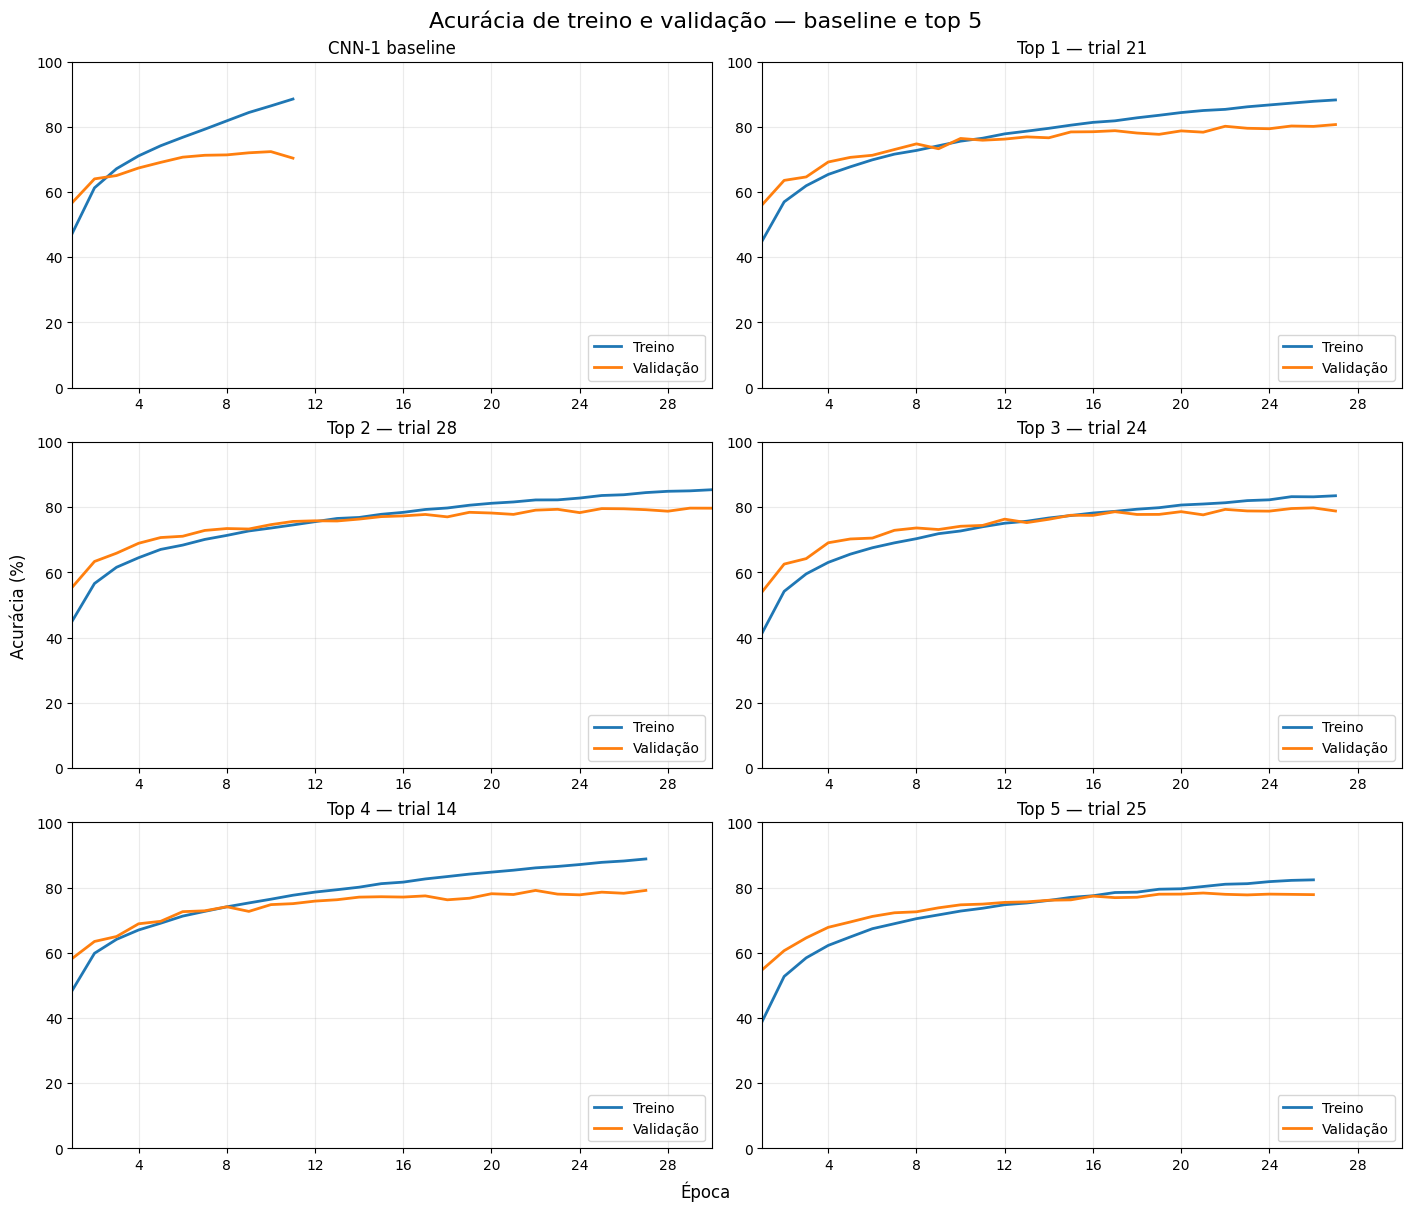

In [37]:
def plot_saved_accuracy(study_name=None, output_path='results/figures/accuracy_top5_baseline.png'):
    import json
    import math
    from pathlib import Path
    import matplotlib.pyplot as plt
    from matplotlib.ticker import MaxNLocator

    root = Path('results/optuna')
    if study_name is None:
        manifests = sorted(root.glob('*/best5.json'))
        if len(manifests) != 1:
            raise ValueError('Informe o study_name dos resultados que deseja visualizar.')
        manifest_path = manifests[0]
    else:
        manifest_path = root / study_name / 'best5.json'
    saved = json.loads(manifest_path.read_text(encoding='utf-8'))
    if len(saved['top5']) != 5:
        raise ValueError('São necessários cinco modelos selecionados e o baseline.')
    entries = [('CNN-1 baseline', saved['baseline'])] + [
        (f"Top {rank} — trial {item['trial_number']}", item['result'])
        for rank, item in enumerate(saved['top5'], 1)
    ]
    curves = []
    for title, result in entries:
        history = result['history']
        if result.get('status') != 'complete' or not history:
            raise ValueError(f'Histórico completo não encontrado: {title}')
        epochs = [row['epoch'] for row in history]
        if epochs != list(range(1, len(history) + 1)):
            raise ValueError(f'Épocas fora de ordem: {title}')
        train_acc = [row['train_acc'] for row in history]
        val_acc = [row['val_acc'] for row in history]
        if any(not math.isfinite(value) or not 0 <= value <= 1
               for value in train_acc + val_acc):
            raise ValueError(f'Acurácia inválida: {title}')
        curves.append((title, epochs, train_acc, val_acc))

    max_epoch = max(len(epochs) for _, epochs, _, _ in curves)
    fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True,
                             sharey=True, constrained_layout=True)
    for ax, (title, epochs, train_acc, val_acc) in zip(axes.flat, curves):
        ax.plot(epochs, [value * 100 for value in train_acc],
                label='Treino', color='tab:blue', linewidth=2)
        ax.plot(epochs, [value * 100 for value in val_acc],
                label='Validação', color='tab:orange', linewidth=2)
        ax.set_title(title)
        ax.set_ylim(0, 100)
        ax.set_xlim(1, max(2, max_epoch))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))
        ax.tick_params(labelbottom=True, labelleft=True)
        ax.grid(alpha=0.25)
        ax.legend(loc='lower right')
    fig.suptitle('Acurácia de treino e validação — baseline e top 5', fontsize=16)
    fig.supxlabel('Época')
    fig.supylabel('Acurácia (%)')
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


plot_saved_accuracy(study.study_name if 'study' in globals() else None)


## Avaliação final no teste oficial

Carregamos o baseline e as duas melhores **topologias distintas** do estudo pela acurácia de validação, com o mesmo critério usado no top 5. O teste não participa da seleção. Todos os modelos recebem os mesmos 10.000 exemplos, em ordem fixa e com a normalização usada no treinamento.

Esta etapa não chama `fit`, `objective` ou `optimize`. Os checkpoints são apenas lidos e os modelos ficam em modo de avaliação. As células abaixo estão prontas para execução; os resultados de teste ainda não foram calculados.

In [38]:
import numpy as np
from torch.utils.data import SequentialSampler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from scipy.stats import binomtest, chi2
from IPython.display import Markdown

ALPHA = 0.05

### Seleção e identificação dos modelos

A seleção é consultada novamente no SQLite, sem criar trials. Reutilizamos `select_best_distinct`, `read_complete`, `ConfigurableCNN`, `count_trainable_parameters` e `comparison_table`. A tabela inclui as configurações salvas; a representação da rede mostra todas as camadas.

In [39]:
def load_checkpoint_model(reference, trial_number=None):
    with torch.random.fork_rng(devices=[]):
        model = build_model(reference['run_config']['architecture'])
    record = read_complete(reference['checkpoint_path'], reference['run_config'], model)
    model.load_state_dict(record['model_state_dict'], strict=True)
    checkpoint = Path(reference['checkpoint_path'])
    description = dict(
        trial=trial_number, run_id=record['run_id'], checkpoint_path=str(checkpoint),
        checkpoint_sha256=hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
        run_config=record['run_config'], topology=str(model),
        trainable_parameters=count_trainable_parameters(model),
        validation_accuracy=record['val_acc'], validation_loss=record['val_loss'],
        best_epoch=record['epoch'], epochs_ran=record['epochs_ran'],
    )
    return model.to(device).eval(), description


def load_final_cnn_models(study_name=None, top_count=2):
    root = Path('results/optuna')
    if study_name is None:
        manifests = sorted(root.glob('*/best5.json'))
        if len(manifests) != 1:
            raise ValueError('Informe o study_name a avaliar.')
        manifest_path = manifests[0]
    else:
        manifest_path = root / study_name / 'best5.json'
    saved = json.loads(manifest_path.read_text(encoding='utf-8'))
    study_name = saved['study_name']
    database = root / 'cnn_studies.sqlite3'
    if not database.is_file():
        raise FileNotFoundError(database)
    saved_study = optuna.load_study(
        study_name=study_name, storage='sqlite:///' + database.resolve().as_posix())
    baseline_reference = saved['baseline']
    baseline_record = read_complete(baseline_reference['checkpoint_path'], baseline_reference['run_config'])
    baseline_result = result_metadata(baseline_record, baseline_reference['checkpoint_path'])
    del baseline_record
    selected = select_best_distinct(saved_study, baseline_result, count=top_count)
    entries = [(f'Top-{rank}', item['trial_number'], item['result'])
               for rank, item in enumerate(selected, 1)]
    entries.append(('Baseline', None, baseline_result))
    models, descriptions = {}, {}
    for name, trial_number, reference in entries:
        models[name], descriptions[name] = load_checkpoint_model(reference, trial_number)
    information = comparison_table(baseline_result, selected)
    information['modelo'] = information['modelo'].replace({
        'CNN-1 baseline': 'Baseline', 'CNN otimizada 1': 'Top-1', 'CNN otimizada 2': 'Top-2',
    })
    return study_name, models, descriptions, information


def check_official_test_loader(loader, descriptions):
    dataset = loader.dataset
    if (not isinstance(dataset, datasets.CIFAR10) or dataset.train
            or len(dataset) != 10_000 or loader.drop_last
            or not isinstance(loader.sampler, SequentialSampler)):
        raise ValueError('Use o CIFAR-10 oficial de teste, completo e sem embaralhamento.')
    classes = list(dataset.classes)
    if len(classes) != 10:
        raise ValueError('O teste deve conter as 10 classes.')
    for description in descriptions.values():
        validation_data = description['run_config']['data']['validation']
        if (validation_data['classes'] != classes
                or validation_data['transform'] != repr(dataset.transform)):
            raise ValueError('Classes ou normalização de teste diferem das usadas no treinamento.')
    return classes


def evaluate_model_predictions(models, loader):
    expected_labels = np.asarray(loader.dataset.targets, dtype=np.int64)
    predictions, rows = {}, []
    for name, model in models.items():
        loss, accuracy, labels, predicted = validate(
            model, loader, nn.CrossEntropyLoss(), device, return_predictions=True)
        labels, predicted = labels.numpy(), predicted.numpy()
        # A igualdade com os rótulos oficiais garante o mesmo pareamento entre modelos.
        if not np.array_equal(labels, expected_labels) or predicted.shape != expected_labels.shape:
            raise ValueError(f'Exemplos ausentes ou ordem de teste incorreta: {name}')
        if np.any((predicted < 0) | (predicted >= 10)):
            raise ValueError(f'Predições fora das 10 classes: {name}')
        correct = predicted == labels
        if not np.isclose(accuracy, correct.mean()):
            raise ValueError('Acurácia e previsões não correspondem.')
        predictions[name] = predicted
        rows.append(dict(modelo=name, acuracia_teste=float(accuracy), loss_teste=float(loss),
                         acertos=int(correct.sum()), total=int(labels.size)))
    return expected_labels, predictions, pd.DataFrame(rows)

### Teste de McNemar

Para cada par, a tabela contém `[[ambos acertam, A acerta/B erra], [A erra/B acerta, ambos erram]]`. O teste usa os pares discordantes de acerto/erro dos mesmos exemplos, mesmo quando os modelos erram escolhendo classes diferentes.

A decisão usa o **McNemar exato bilateral**, com α = 0,05, sem ajuste por comparações múltiplas. A estatística exata é `min(b, c)`; mostramos também o χ² com correção de continuidade `max(|b−c|−1, 0)² / (b+c)` e seu p-valor como referência. Sem discordâncias, usamos estatística 0 e p = 1. Não rejeitar H₀ não prova equivalência. A comparação Top-1 × Top-2 é principal; Top-1 × baseline é adicional.

Referências: [McNemar no statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.contingency_tables.mcnemar.html) e [matriz de confusão no scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).

O p-valor exato é calculado com [scipy.stats.binomtest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html), condicionado às discordâncias, com probabilidade 0,5 sob H₀.

In [40]:
def compare_mcnemar(labels, predictions, name_a, name_b, alpha=0.05):
    if not 0 < alpha < 1:
        raise ValueError('alpha deve estar entre 0 e 1.')
    correct_a = predictions[name_a] == labels
    correct_b = predictions[name_b] == labels
    if correct_a.shape != labels.shape or correct_b.shape != labels.shape:
        raise ValueError('As previsões devem corresponder aos mesmos exemplos.')
    a = int(np.sum(correct_a & correct_b))
    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))
    d = int(np.sum(~correct_a & ~correct_b))
    counts = np.array([[a, b], [c, d]], dtype=np.int64)
    if counts.sum() != labels.size:
        raise ValueError('A tabela não corresponde ao total de exemplos.')
    if b + c == 0:
        exact_statistic, exact_p, chi2_statistic, chi2_p = 0.0, 1.0, 0.0, 1.0
    else:
        # Sob H₀, cada discordância favorece A ou B com probabilidade 0,5.
        exact_statistic = float(min(b, c))
        exact_p = float(binomtest(b, n=b + c, p=0.5, alternative='two-sided').pvalue)
        chi2_statistic = float(max(abs(b - c) - 1, 0) ** 2 / (b + c))
        chi2_p = float(chi2.sf(chi2_statistic, df=1))
    reject = exact_p < alpha
    if reject:
        higher = name_a if b > c else name_b
        interpretation = (f'Rejeita H₀: há evidência de taxas de acerto diferentes; '
                          f'{higher} apresentou maior acurácia neste teste.')
    else:
        interpretation = ('Não rejeita H₀: não há evidência suficiente de diferença '
                          'nas taxas de acerto. Isso não demonstra equivalência.')
    table = pd.DataFrame(counts,
        index=[f'{name_a}: acerto', f'{name_a}: erro'],
        columns=[f'{name_b}: acerto', f'{name_b}: erro'])
    summary = dict(
        comparacao=f'{name_a} × {name_b}', modelo_a=name_a, modelo_b=name_b,
        ambos_acertam=a, somente_a_acerta=b, somente_b_acerta=c, ambos_erram=d,
        discordancias=b + c, estatistica_exata_min_bc=exact_statistic,
        p_valor_exato=exact_p, estatistica_chi2_corrigida=chi2_statistic,
        p_valor_chi2=chi2_p, alpha=float(alpha), rejeita_h0=bool(reject),
        metodo_decisao='McNemar exato bilateral', interpretacao=interpretation,
    )
    return table, summary


def save_final_confusion_matrices(labels, predictions, classes, descriptions, directory, model_names=None):
    matrices = {}
    names = list(model_names) if model_names is not None else ['Top-1', 'Top-2']
    if not names:
        raise ValueError('Selecione ao menos um modelo para as matrizes.')
    fig, axes = plt.subplots(1, len(names), figsize=(9 * len(names), 7),
                             squeeze=False, constrained_layout=True)
    for name, ax in zip(names, axes.flat):
        matrix = confusion_matrix(labels, predictions[name], labels=np.arange(len(classes)))
        matrices[name] = matrix.tolist()
        frame = pd.DataFrame(matrix, index=classes, columns=classes)
        frame.index.name = 'classe_real'
        atomic_text(frame.to_csv(lineterminator='\n'), directory / f"confusion_{name.lower().replace(' ', '_')}.csv")
        ConfusionMatrixDisplay(matrix, display_labels=classes).plot(
            ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45, values_format='d')
        trial_number = descriptions[name]['trial']
        ax.set_title(name if trial_number is None else f'{name} — trial {trial_number}')
        ax.set_xlabel('Classe prevista')
        ax.set_ylabel('Classe real')
    fig.suptitle('Matrizes de confusão — teste oficial do CIFAR-10')
    fig.savefig(directory / 'confusion_matrices.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return matrices

### Executar a avaliação final

A chamada abaixo carrega os checkpoints, mostra as três redes e suas configurações, faz a inferência no teste e exibe acurácias, matrizes e resultados estatísticos. Os comentários e interpretações usam as métricas calculadas nesta execução.

Salvamos informações dos modelos, acurácias, previsões individuais por índice, matrizes e resultados de McNemar em `results/evaluation/<estudo>/<identificador>/`. O identificador inclui os checkpoints e os dados de teste; nenhum modelo treinado é sobrescrito.

In [41]:
def evaluate_and_report_models(models, descriptions, information, study_name,
                               comparisons, output_root, alpha=ALPHA, confusion_names=None):
    if not 0 < alpha < 1:
        raise ValueError('alpha deve estar entre 0 e 1.')
    class_names = check_official_test_loader(test_loader, descriptions)
    test_description = dict(
        dataset='CIFAR10', split='official_test', size=len(test_loader.dataset),
        classes=class_names, transform=repr(test_loader.dataset.transform),
        targets_sha256=config_id(list(map(int, test_loader.dataset.targets))),
        batch_size=test_loader.batch_size, order='SequentialSampler',
    )
    identity = dict(version=1, study_name=study_name, test=test_description, alpha=float(alpha),
                    models={name: dict(run_id=value['run_id'], sha256=value['checkpoint_sha256'])
                            for name, value in descriptions.items()})
    directory = Path(output_root) / study_name / config_id(identity)
    directory.mkdir(parents=True, exist_ok=True)
    atomic_json(descriptions, directory / 'model_information.json')
    atomic_text(information.to_csv(index=False, lineterminator='\n'), directory / 'model_information.csv')
    display(Markdown('**Modelos selecionados por validação e suas configurações**'))
    with pd.option_context('display.max_columns', None, 'display.max_colwidth', None):
        display(information.drop(columns=['topology_id', 'checkpoint'], errors='ignore'))
    for name, model in models.items():
        print(f'{name} — {count_trainable_parameters(model):,} parâmetros treináveis')
        print(model)

    labels, predictions, metrics = evaluate_model_predictions(models, test_loader)
    parameter_rows = [dict(modelo=name, parametros_treinaveis=description['trainable_parameters'],
                           acuracia_validacao=description['validation_accuracy'])
                      for name, description in descriptions.items()]
    metrics = metrics.merge(pd.DataFrame(parameter_rows), on='modelo', validate='one_to_one')
    atomic_text(metrics.to_csv(index=False, lineterminator='\n'), directory / 'test_metrics.csv')
    prediction_frame = pd.DataFrame(dict(sample_index=np.arange(labels.size), label=labels,
                                         classe_real=[class_names[i] for i in labels]))
    for name, predicted in predictions.items():
        prediction_frame[f'{name}_prediction'] = predicted
        prediction_frame[f'{name}_correct'] = predicted == labels
    atomic_text(prediction_frame.to_csv(index=False, lineterminator='\n'), directory / 'test_predictions.csv')
    display(Markdown('**Acurácia no teste oficial**'))
    display(metrics.style.format({'acuracia_teste': '{:.2%}', 'loss_teste': '{:.4f}'}))
    matrices = save_final_confusion_matrices(
        labels, predictions, class_names, descriptions, directory, model_names=confusion_names)
    atomic_json(dict(classes=class_names, orientation='rows=true, columns=predicted', matrices=matrices),
                directory / 'confusion_matrices.json')

    summaries, tables = [], {}
    for name_a, name_b, slug in comparisons:
        table, summary = compare_mcnemar(labels, predictions, name_a, name_b, alpha)
        tables[slug] = table.to_numpy().tolist()
        summaries.append(summary)
        atomic_text(table.to_csv(lineterminator='\n'), directory / f'mcnemar_{slug}_table.csv')
        display(Markdown(f"**Concordância/discordância: {summary['comparacao']}**"))
        display(table)
    statistics = pd.DataFrame(summaries)
    atomic_text(statistics.to_csv(index=False, lineterminator='\n'), directory / 'mcnemar_results.csv')
    atomic_json(dict(alpha=float(alpha), decision_method='exact_two_sided',
                     multiple_testing_correction='none', tables=tables, results=summaries),
                directory / 'mcnemar_results.json')
    atomic_json(dict(identity=identity, model_information=descriptions,
                     test_metrics=metrics.to_dict(orient='records')),
                directory / 'test_metrics.json')
    display(Markdown('**McNemar: estatísticas e p-valores (decisão pelo p-valor exato)**'))
    display(statistics[['comparacao', 'estatistica_exata_min_bc', 'p_valor_exato',
                        'estatistica_chi2_corrigida', 'p_valor_chi2', 'alpha', 'rejeita_h0']])
    for summary in summaries:
        display(Markdown(f"**{summary['comparacao']}** — {summary['interpretacao']}"))
    return dict(directory=str(directory), model_information=information, metrics=metrics,
                predictions=prediction_frame, mcnemar=statistics)


def run_final_evaluation(study_name=None, alpha=ALPHA):
    study_name, models, descriptions, information = load_final_cnn_models(study_name)
    return evaluate_and_report_models(
        models, descriptions, information, study_name,
        comparisons=[('Top-1', 'Top-2', 'top1_vs_top2'),
                     ('Top-1', 'Baseline', 'top1_vs_baseline')],
        output_root='results/evaluation', alpha=alpha, confusion_names=['Top-1', 'Top-2'])

**Modelos selecionados por validação e suas configurações**

,modelo,trial,blocos,filtros,kernel,batch_norm,dropout,fully_connected,otimizador,learning_rate,parametros_otimizador,batch_size,max_epochs,patience,melhor_epoca,epocas_executadas,acuracia_validacao,loss_validacao,parametros_treinaveis
0,Baseline,NaN,2,"[32, 64]",3,False,0.000000,[128],Adam,0.001000,"{""amsgrad"":false,""betas"":[0.9,0.999],""capturable"":false,""decoupled_weight_decay"":false,""differentiable"":false,""eps"":1e-08,""foreach"":null,""fused"":null,""lr"":0.001,""maximize"":false,""weight_decay"":0}",128,30,5,6,11,0.7066,0.857878,545098
1,Top-1,21.0,3,"[128, 128, 128]",3,True,0.163208,"[512, 512]",RMSprop,0.000131,"{""alpha"":0.99,""capturable"":false,""centered"":false,""differentiable"":false,""eps"":1e-08,""foreach"":null,""lr"":0.00013127236120214395,""maximize"":false,""momentum"":0,""weight_decay"":0}",128,30,5,22,27,0.8014,0.607003,1616394
2,Top-2,28.0,3,"[128, 128, 32]",3,True,0.155631,"[512, 512]",RMSprop,0.000201,"{""alpha"":0.99,""capturable"":false,""centered"":false,""differentiable"":false,""eps"":1e-08,""foreach"":null,""lr"":0.00020096902044204216,""maximize"":false,""momentum"":0,""weight_decay"":0}",128,30,5,25,30,0.7956,0.599402,719082


Top-1 — 1,616,394 parâmetros treináveis
ConfigurableCNN(
  (features): Sequential(
    (0): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.1632081513046253, inplace=False)
    (5): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout2d(p=0.1632081513046253, inplace=False)
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  

**Acurácia no teste oficial**

,modelo,acuracia_teste,loss_teste,acertos,total,parametros_treinaveis,acuracia_validacao
0,Top-1,79.19%,0.6248,7919,10000,1616394,0.801400
1,Top-2,78.87%,0.6223,7887,10000,719082,0.795600
2,Baseline,70.85%,0.8623,7085,10000,545098,0.706600


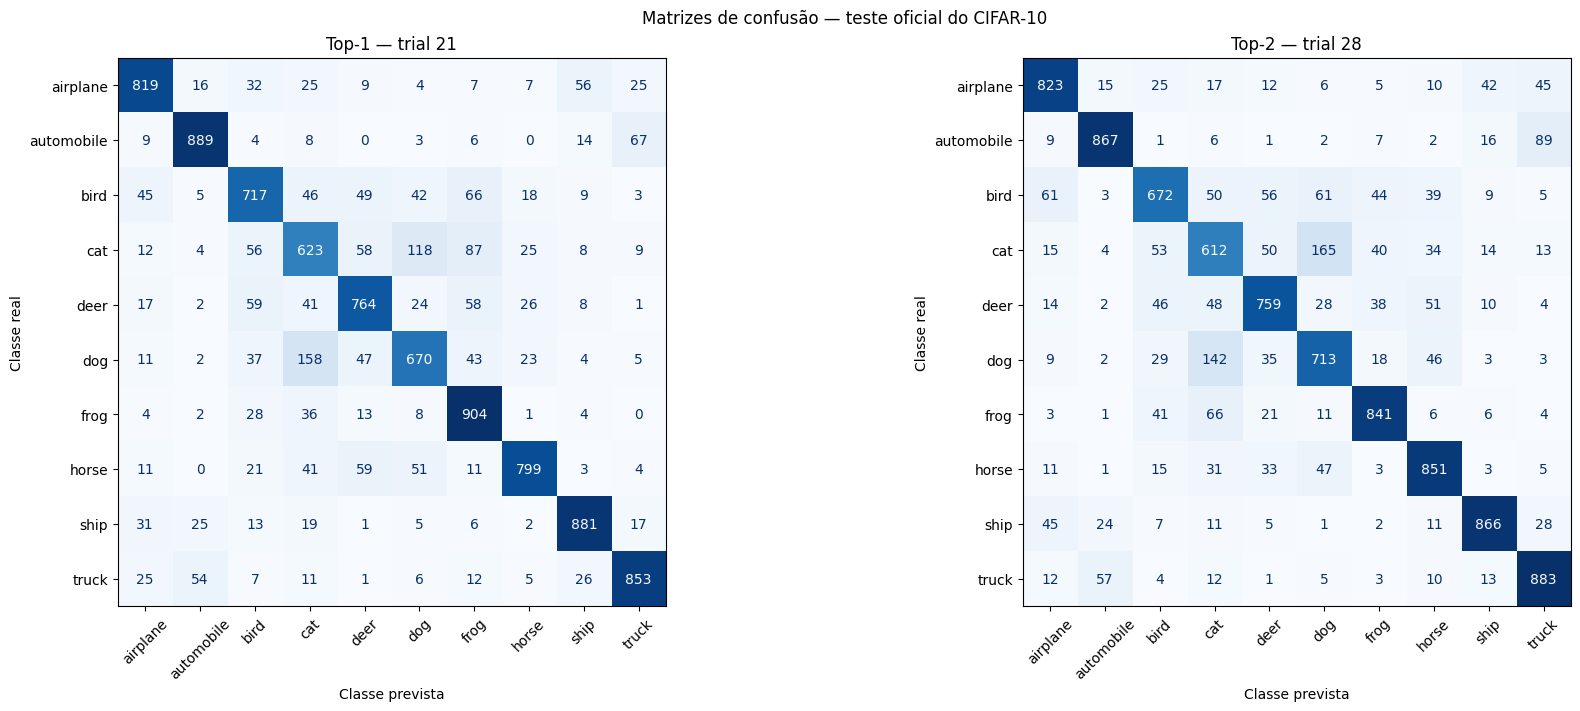

**Concordância/discordância: Top-1 × Top-2**

,Top-2: acerto,Top-2: erro
Top-1: acerto,7261,658
Top-1: erro,626,1455


**Concordância/discordância: Top-1 × Baseline**

,Baseline: acerto,Baseline: erro
Top-1: acerto,6586,1333
Top-1: erro,499,1582


**McNemar: estatísticas e p-valores (decisão pelo p-valor exato)**

,comparacao,estatistica_exata_min_bc,p_valor_exato,estatistica_chi2_corrigida,p_valor_chi2,alpha,rejeita_h0
0,Top-1 × Top-2,626.0,3.869776e-01,0.748442,3.869698e-01,0.05,False
1,Top-1 × Baseline,499.0,1.847776e-87,378.760371,2.316589e-84,0.05,True


**Top-1 × Top-2** — Não rejeita H₀: não há evidência suficiente de diferença nas taxas de acerto. Isso não demonstra equivalência.

**Top-1 × Baseline** — Rejeita H₀: há evidência de taxas de acerto diferentes; Top-1 apresentou maior acurácia neste teste.

In [42]:
final_evaluation = run_final_evaluation(study.study_name if 'study' in globals() else None)

## MLP configurável no CIFAR-10

A MLP recebe as mesmas imagens RGB normalizadas das CNNs. `Flatten` transforma cada imagem em 3.072 características; as camadas ocultas usam ReLU e Dropout opcional. A saída tem 10 logits, sem Softmax.

Reutilizamos `run_experiment`, `fit`, `train_one_epoch` e `validate`, com as mesmas divisões e seed. O tipo MLP integra a configuração do checkpoint e seus arquivos ficam em `results/models/mlp/`, separados das CNNs.

In [43]:
class ConfigurableMLP(nn.Module):
    def __init__(self, hidden_layers=(256,), dropout=0.0):
        super().__init__()
        hidden_layers = tuple(hidden_layers)
        if not hidden_layers or any(type(width) is not int or width <= 0 for width in hidden_layers):
            raise ValueError('Informe camadas ocultas com tamanhos inteiros positivos.')
        if not isinstance(dropout, (int, float)) or not 0 <= dropout < 1:
            raise ValueError('dropout deve estar entre 0 (inclusivo) e 1 (exclusivo).')
        self.config = dict(model_type='MLP', hidden_layers=hidden_layers, dropout=float(dropout))
        layers = [nn.Flatten(start_dim=1)]
        in_features = 3 * 32 * 32
        for width in hidden_layers:
            layers.extend([nn.Linear(in_features, width), nn.ReLU()])
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            in_features = width
        layers.append(nn.Linear(in_features, 10))
        self.classifier = nn.Sequential(*layers)

    def forward(self, x):
        return self.classifier(x)

### Otimização da MLP por validação

São 10 trials no total, até 30 épocas por treino, paciência 5 e batch size 128. Testamos 1–3 camadas ocultas, 128/256/512 neurônios por camada, Dropout 0/0,2/0,4, Adam/AdamW e learning rate logarítmico entre 0,0001 e 0,003. Os três primeiros pontos cobrem as três profundidades; os demais são sugeridos pelo Optuna.

Maximizamos a acurácia de validação dos pesos de menor loss de validação, com o mesmo critério das CNNs. O teste não participa. O SQLite é próprio da MLP. Checkpoints parciais não contam como treinos concluídos; repetições de uma configuração completa usam seu cache.

`best_mlp.json` guarda a melhor configuração e o caminho do checkpoint completo original. O CSV dos trials preserva parâmetros, estados e métricas.

Retomar a busca consome somente o orçamento restante dos 10 trials; os concluídos não são executados novamente. Use uma instância do notebook por vez.

In [44]:
MLP_TRIALS = 10
MLP_HIDDEN_OPTIONS = [128, 256, 512]
MLP_DROPOUT_OPTIONS = [0.0, 0.2, 0.4]


def suggest_mlp_configuration(trial):
    depth = trial.suggest_int('num_hidden_layers', 1, 3)
    architecture = dict(
        model_type='MLP',
        hidden_layers=[trial.suggest_categorical(f'hidden_{i}', MLP_HIDDEN_OPTIONS)
                       for i in range(depth)],
        dropout=trial.suggest_categorical('dropout', MLP_DROPOUT_OPTIONS),
    )
    training = dict(
        lr=trial.suggest_float('lr', 1e-4, 3e-3, log=True),
        optimizer=trial.suggest_categorical('optimizer', ['Adam', 'AdamW']), batch_size=128,
    )
    return architecture, training


def mlp_objective(trial):
    architecture, training = suggest_mlp_configuration(trial)
    trial.set_user_attr('architecture', architecture)
    trial.set_user_attr('training', training)
    result = run_experiment(architecture, training, model_root='results/models/mlp')
    return record_trial_result(trial, result)


def select_best_mlp(mlp_study):
    completed = sorted(
        (trial for trial in mlp_study.get_trials(deepcopy=False)
         if trial.state == optuna.trial.TrialState.COMPLETE and trial.value is not None),
        key=lambda trial: (-trial.value, trial.number),
    )
    if not completed:
        raise RuntimeError('Nenhum trial MLP foi concluído com sucesso.')
    best = completed[0]
    config = best.user_attrs['run_config']
    if config['architecture'].get('model_type') != 'MLP':
        raise ValueError('O estudo não corresponde a modelos MLP.')
    path = best.user_attrs['checkpoint_path']
    record = read_complete(path, config)
    if record['val_acc'] != best.value or record['run_id'] != best.user_attrs['run_id']:
        raise ValueError('O checkpoint da melhor MLP não corresponde ao trial.')
    result = result_metadata(record, path)
    result['trial_number'] = best.number
    return best.number, result


def _run_mlp_search():
    protocol = dict(
        version=1, seed=SEED, max_epochs=30, patience=5, batch_size=128,
        objective='val_acc_at_minimum_val_loss',
        data=dict(train=dataset_signature(train_loader), validation=dataset_signature(val_loader)),
        search_space=dict(hidden_layers=[1, 2, 3], widths=MLP_HIDDEN_OPTIONS,
                          dropout=MLP_DROPOUT_OPTIONS, lr=[1e-4, 3e-3],
                          lr_log=True, optimizers=['Adam', 'AdamW']),
    )
    root = Path('results/optuna')
    root.mkdir(parents=True, exist_ok=True)
    study_name = 'cifar10_mlp_v1_' + config_id(protocol)[:16]
    storage = optuna.storages.RDBStorage(
        url='sqlite:///' + (root / 'mlp_studies.sqlite3').resolve().as_posix(),
        engine_kwargs={'connect_args': {'timeout': 60}},
    )
    mlp_study = optuna.create_study(
        study_name=study_name, storage=storage, direction='maximize', load_if_exists=True,
        sampler=optuna.samplers.TPESampler(seed=SEED), pruner=optuna.pruners.NopPruner())
    if mlp_study.user_attrs.get('protocol', protocol) != protocol:
        raise ValueError('Protocolo incompatível com o estudo MLP persistido.')
    mlp_study.set_user_attr('protocol', protocol)
    directory = root / study_name
    directory.mkdir(parents=True, exist_ok=True)
    if not mlp_study.get_trials(deepcopy=False):
        for widths, dropout in [([128], 0.0), ([256, 256], 0.2), ([512, 256, 128], 0.4)]:
            params = dict(num_hidden_layers=len(widths), dropout=dropout,
                          optimizer='Adam' if len(widths) != 2 else 'AdamW', lr=0.001)
            params.update({f'hidden_{i}': width for i, width in enumerate(widths)})
            mlp_study.enqueue_trial(params)
    run_remaining_trials(mlp_study, mlp_objective, MLP_TRIALS, directory)
    atomic_text(mlp_study.trials_dataframe().to_csv(index=False, lineterminator=chr(10)), directory / 'trials.csv')
    trial_number, result = select_best_mlp(mlp_study)
    atomic_json(dict(study_name=study_name, best_trial=trial_number,
                     trial_budget=MLP_TRIALS, protocol=protocol, result=result), directory / 'best_mlp.json')
    return mlp_study, result


def run_mlp_search():
    mlp_study, result = quiet_run(_run_mlp_search)
    architecture = result['run_config']['architecture']
    training = result['run_config']['training']
    table = pd.DataFrame([dict(
        trial=result['trial_number'], camadas_ocultas=str(architecture['hidden_layers']),
        dropout=architecture['dropout'], otimizador=training['optimizer'],
        learning_rate=training['optimizer_params']['lr'], batch_size=training['batch_size'],
        max_epochs=training['max_epochs'], patience=training['patience'],
        parametros_treinaveis=result['trainable_parameters'], acuracia_validacao=result['val_acc'],
    )])
    display(table.style.format({'acuracia_validacao': '{:.2%}'}))
    return mlp_study, result

In [45]:
mlp_study, best_mlp = run_mlp_search()

,trial,camadas_ocultas,dropout,otimizador,learning_rate,batch_size,max_epochs,patience,parametros_treinaveis,acuracia_validacao
0,8,[512],0.400000,AdamW,0.000336,128,30,5,1578506,55.88%


### Comparação final: MLP × melhor CNN × baseline

A melhor MLP e a melhor CNN são escolhidas pela validação, antes de olhar o teste. As CNNs são carregadas dos checkpoints existentes: esta comparação não chama treino ou otimização. Conferimos que os três treinos usaram as mesmas divisões e normalização.

A inferência e o relatório são compartilhados com a avaliação anterior. As três matrizes usam as 10 classes; McNemar compara acertos/erros das mesmas imagens para MLP × melhor CNN e MLP × baseline, com α = 0,05. A tabela e o gráfico relacionam a acurácia oficial de teste com os parâmetros treináveis. Resultados ficam em `results/mlp_comparison/`.

In [46]:
def load_best_mlp_model(study_name=None):
    root = Path('results/optuna')
    database = root / 'mlp_studies.sqlite3'
    if not database.is_file():
        raise FileNotFoundError('Execute a busca MLP para produzir o estudo e os checkpoints.')
    if study_name is None:
        manifests = sorted(root.glob('*/best_mlp.json'))
        if len(manifests) != 1:
            raise ValueError('Informe o study_name MLP a comparar.')
        study_name = json.loads(manifests[0].read_text(encoding='utf-8'))['study_name']
    saved_study = optuna.load_study(
        study_name=study_name, storage='sqlite:///' + database.resolve().as_posix())
    trial_number, result = select_best_mlp(saved_study)
    model, description = load_checkpoint_model(result, trial_number)
    return study_name, model, description


def model_information_table(descriptions):
    rows = []
    for name, description in descriptions.items():
        config = description['run_config']
        rows.append(dict(
            modelo=name, tipo=config['architecture'].get('model_type', 'CNN'),
            trial=description['trial'], topologia=canonical_json(config['architecture']),
            hiperparametros=canonical_json(config['training']),
            parametros_treinaveis=description['trainable_parameters'],
            acuracia_validacao=description['validation_accuracy'],
            melhor_epoca=description['best_epoch'], epocas_executadas=description['epochs_ran'],
        ))
    return pd.DataFrame(rows)


def plot_accuracy_vs_parameters(metrics, directory):
    from matplotlib.ticker import FuncFormatter

    fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
    colors = ['tab:purple', 'tab:blue', 'tab:orange']
    markers = ['s', 'o', '^']
    for (name, count, accuracy), color, marker in zip(
            metrics[['modelo', 'parametros_treinaveis', 'acuracia_teste']].itertuples(index=False, name=None),
            colors, markers):
        ax.scatter(count, accuracy * 100, color=color, marker=marker, s=110, zorder=3)
        ax.annotate(f'{name}: {accuracy:.2%}', (count, accuracy * 100),
                    xytext=(8, 10), textcoords='offset points')
    ax.set_xscale('log')
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda value, position: f'{value / 1e6:g} M' if value >= 1e6 else f'{value / 1e3:g} mil'))
    ax.set_ylim(0, 100)
    ax.margins(x=0.3)
    ax.set_xlabel('Parâmetros treináveis (escala logarítmica)')
    ax.set_ylabel('Acurácia no teste (%)')
    ax.set_title('MLP e CNNs — acurácia versus número de parâmetros')
    ax.grid(alpha=0.25)
    fig.savefig(Path(directory) / 'accuracy_vs_parameters.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def compare_mlp_and_cnn(mlp_study_name=None, cnn_study_name=None, alpha=ALPHA):
    mlp_name, mlp_model, mlp_description = load_best_mlp_model(mlp_study_name)
    cnn_name, cnn_models, cnn_descriptions, _ = load_final_cnn_models(cnn_study_name, top_count=1)
    models = {'MLP': mlp_model, 'Melhor CNN': cnn_models['Top-1'], 'Baseline': cnn_models['Baseline']}
    descriptions = {'MLP': mlp_description, 'Melhor CNN': cnn_descriptions['Top-1'],
                    'Baseline': cnn_descriptions['Baseline']}
    expected_data = mlp_description['run_config']['data']
    if any(description['run_config']['data'] != expected_data for description in descriptions.values()):
        raise ValueError('Os modelos devem usar as mesmas divisões e o mesmo pré-processamento.')
    information = model_information_table(descriptions)
    report = evaluate_and_report_models(
        models, descriptions, information, mlp_name,
        comparisons=[('MLP', 'Melhor CNN', 'mlp_vs_best_cnn'), ('MLP', 'Baseline', 'mlp_vs_baseline')],
        output_root='results/mlp_comparison', alpha=alpha,
        confusion_names=['MLP', 'Melhor CNN', 'Baseline'])
    directory = Path(report['directory'])
    atomic_json(dict(mlp_study=mlp_name, cnn_study=cnn_name), directory / 'studies.json')
    table = report['metrics'][['modelo', 'parametros_treinaveis', 'acuracia_validacao', 'acuracia_teste']]
    atomic_text(table.to_csv(index=False, lineterminator=chr(10)), directory / 'accuracy_vs_parameters.csv')
    display(Markdown('**Acurácia versus parâmetros treináveis**'))
    display(table.style.format({'acuracia_validacao': '{:.2%}', 'acuracia_teste': '{:.2%}',
                                'parametros_treinaveis': '{:,}'}))
    plot_accuracy_vs_parameters(table, directory)
    return report

**Modelos selecionados por validação e suas configurações**

,modelo,tipo,trial,topologia,hiperparametros,parametros_treinaveis,acuracia_validacao,melhor_epoca,epocas_executadas
0,MLP,MLP,8.0,"{""dropout"":0.4,""hidden_layers"":[512],""model_type"":""MLP""}","{""batch_size"":128,""loss"":{""label_smoothing"":0.0,""name"":""CrossEntropyLoss"",""reduction"":""mean"",""weight"":null},""max_epochs"":30,""optimizer"":""AdamW"",""optimizer_params"":{""amsgrad"":false,""betas"":[0.9,0.999],""capturable"":false,""decoupled_weight_decay"":true,""differentiable"":false,""eps"":1e-08,""foreach"":null,""fused"":null,""lr"":0.0003364867144187955,""maximize"":false,""weight_decay"":0.01},""patience"":5,""seed"":42,""selection"":""minimum_val_loss""}",1578506,0.5588,21,26
1,Melhor CNN,CNN,21.0,"{""batch_norm"":true,""dropout"":0.1632081513046253,""fc_layers"":[512,512],""filters"":[128,128,128],""kernel_size"":3,""num_blocks"":3}","{""batch_size"":128,""loss"":{""label_smoothing"":0.0,""name"":""CrossEntropyLoss"",""reduction"":""mean"",""weight"":null},""max_epochs"":30,""optimizer"":""RMSprop"",""optimizer_params"":{""alpha"":0.99,""capturable"":false,""centered"":false,""differentiable"":false,""eps"":1e-08,""foreach"":null,""lr"":0.00013127236120214395,""maximize"":false,""momentum"":0,""weight_decay"":0},""patience"":5,""seed"":42,""selection"":""minimum_val_loss""}",1616394,0.8014,22,27
2,Baseline,CNN,NaN,"{""batch_norm"":false,""dropout"":0.0,""fc_layers"":[128],""filters"":[32,64],""kernel_size"":3,""num_blocks"":2}","{""batch_size"":128,""loss"":{""label_smoothing"":0.0,""name"":""CrossEntropyLoss"",""reduction"":""mean"",""weight"":null},""max_epochs"":30,""optimizer"":""Adam"",""optimizer_params"":{""amsgrad"":false,""betas"":[0.9,0.999],""capturable"":false,""decoupled_weight_decay"":false,""differentiable"":false,""eps"":1e-08,""foreach"":null,""fused"":null,""lr"":0.001,""maximize"":false,""weight_decay"":0},""patience"":5,""seed"":42,""selection"":""minimum_val_loss""}",545098,0.7066,6,11


MLP — 1,578,506 parâmetros treináveis
ConfigurableMLP(
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)
Melhor CNN — 1,616,394 parâmetros treináveis
ConfigurableCNN(
  (features): Sequential(
    (0): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout2d(p=0.1632081513046253, inplace=False)
    (5): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropo

**Acurácia no teste oficial**

,modelo,acuracia_teste,loss_teste,acertos,total,parametros_treinaveis,acuracia_validacao
0,MLP,55.00%,1.3104,5500,10000,1578506,0.558800
1,Melhor CNN,79.19%,0.6248,7919,10000,1616394,0.801400
2,Baseline,70.85%,0.8623,7085,10000,545098,0.706600


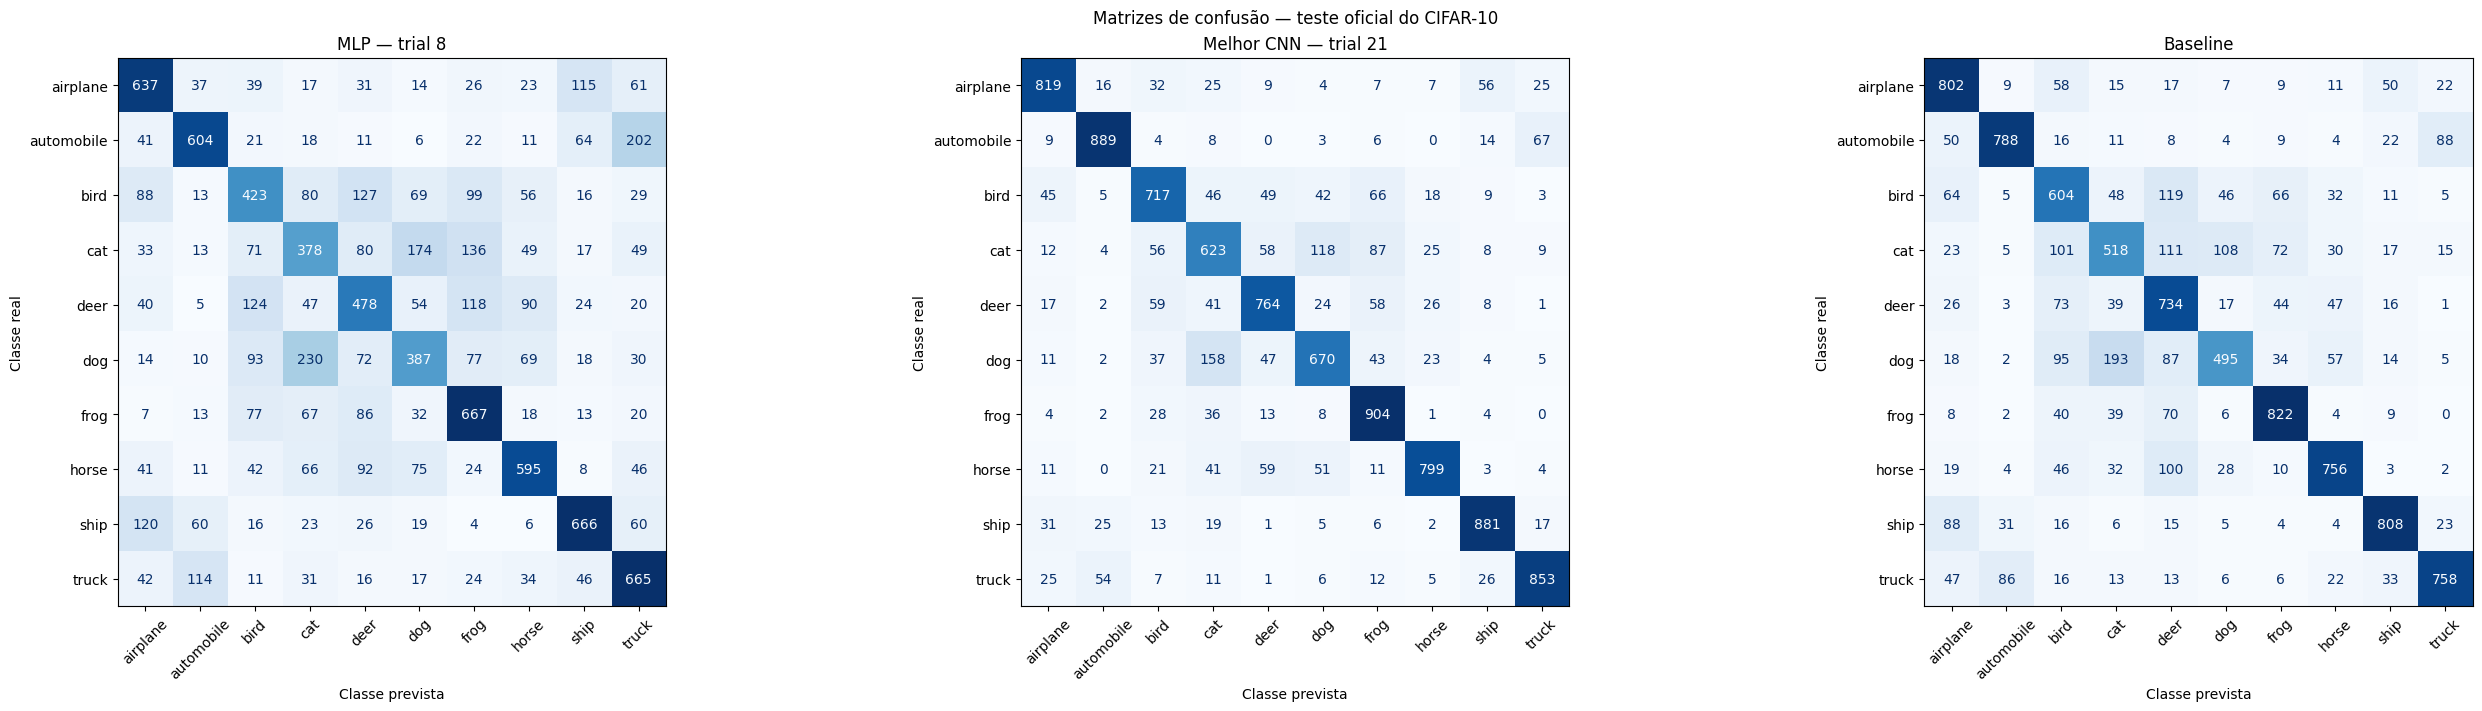

**Concordância/discordância: MLP × Melhor CNN**

,Melhor CNN: acerto,Melhor CNN: erro
MLP: acerto,5064,436
MLP: erro,2855,1645


**Concordância/discordância: MLP × Baseline**

,Baseline: acerto,Baseline: erro
MLP: acerto,4822,678
MLP: erro,2263,2237


**McNemar: estatísticas e p-valores (decisão pelo p-valor exato)**

,comparacao,estatistica_exata_min_bc,p_valor_exato,estatistica_chi2_corrigida,p_valor_chi2,alpha,rejeita_h0
0,MLP × Melhor CNN,436.0,0.000000e+00,1776.579763,0.000000e+00,0.05,True
1,MLP × Baseline,678.0,9.713300e-198,853.130228,1.517224e-187,0.05,True


**MLP × Melhor CNN** — Rejeita H₀: há evidência de taxas de acerto diferentes; Melhor CNN apresentou maior acurácia neste teste.

**MLP × Baseline** — Rejeita H₀: há evidência de taxas de acerto diferentes; Baseline apresentou maior acurácia neste teste.

**Acurácia versus parâmetros treináveis**

,modelo,parametros_treinaveis,acuracia_validacao,acuracia_teste
0,MLP,"1,578,506",55.88%,55.00%
1,Melhor CNN,"1,616,394",80.14%,79.19%
2,Baseline,"545,098",70.66%,70.85%


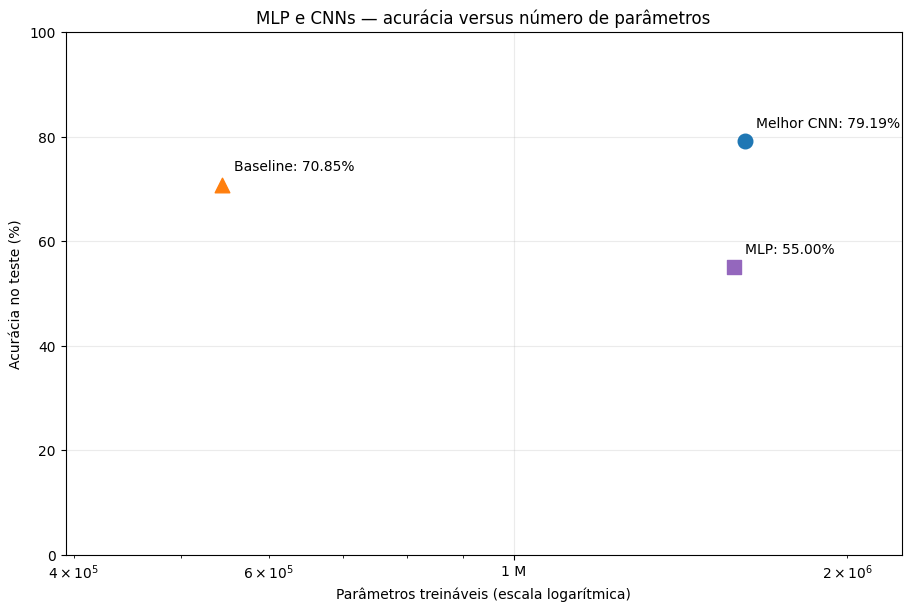

In [47]:
mlp_cnn_comparison = compare_mlp_and_cnn(
    mlp_study.study_name if 'mlp_study' in globals() else None,
    study.study_name if 'study' in globals() else None,
)